# 52 · Massively parallel simulation with MJX: thousands of Unitree Go1s on one GPU (run on Colab GPU)

In [1]:
!pip install -q "playground==0.2.0" "jax[cuda12]==0.7.2" "flax==0.11.2" "orbax-checkpoint==0.11.22" mediapy
import os
os.environ["XLA_PYTHON_CLIENT_PREALLOCATE"] = "false"
os.environ["MUJOCO_GL"] = "egl"

In [2]:
import time, functools, jax, jax.numpy as jp, numpy as np, mujoco, mediapy as media, matplotlib.pyplot as plt
from mujoco import mjx
from mujoco_playground import registry
print("devices:", jax.devices())

def bench(step_fn, state, n=100):
    state = step_fn(state); jax.block_until_ready(state)
    t0 = time.perf_counter()
    for _ in range(n):
        state = step_fn(state)
    jax.block_until_ready(state)
    return (time.perf_counter() - t0) / n

/usr/local/lib/python3.13/dist-packages/jaxlib/plugin_support.py:71: RuntimeWarning: JAX plugin jax_cuda13_plugin version 0.11.1 is installed, but it is not compatible with the installed jaxlib version 0.7.2, so it will not be used.
  warnings.warn(
ERROR:2026-11-10 11:00:38,233:jax._src.xla_bridge:487: Jax plugin configuration error: Exception when calling jax_plugins.xla_cuda12.initialize()
Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/jax/_src/xla_bridge.py", line 485, in discover_pjrt_plugins
    plugin_module.initialize()
    ~~~~~~~~~~~~~~~~~~~~~~~~^^
  File "/usr/local/lib/python3.13/dist-packages/jax_plugins/xla_cuda12/__init__.py", line 344, in initialize
    for _name, _value in cuda_plugin_extension.ffi_registrations().items():
                         ^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
AttributeError: module 'jax_cuda13_plugin.cuda_plugin_extension' has no attribute 'ffi_registrations'
ERROR:jax._src.xla_bridge:Jax plugin configurat

devices: [CudaDevice(id=0)]


In [3]:
env = registry.load("Go1JoystickFlatTerrain")
mj_model = env.mj_model
mx = mjx.put_model(mj_model)
print(f"Go1: nq={mj_model.nq} nv={mj_model.nv} nu={mj_model.nu}  sim dt={env.sim_dt}  control dt={env.dt}")

mujoco_menagerie not found. Downloading...


Cloning mujoco_menagerie: ██████████| 100/100 [00:48<00:00]


Checking out commit 1b86ece576591213e2b666ebf59508454200ca97
Successfully downloaded mujoco_menagerie
Warp 1.19.0 initialized:
   CUDA Toolkit 13.4, Driver 13.0
   Devices:
     "cpu"      : "x86_64"
     "cuda:0"   : "Tesla T4" (15 GiB, sm_75, mempool enabled)
   Kernel cache:
     /root/.cache/warp/1.19.0
Go1: nq=19 nv=18 nu=12  sim dt=0.004  control dt=0.02


CPU MuJoCo, 1 env              27,910 steps/s
MJX, 1 envs                         1 steps/s
MJX, 128 envs                     103 steps/s
MJX, 1024 envs                    582 steps/s
MJX, 4096 envs                  2,000 steps/s


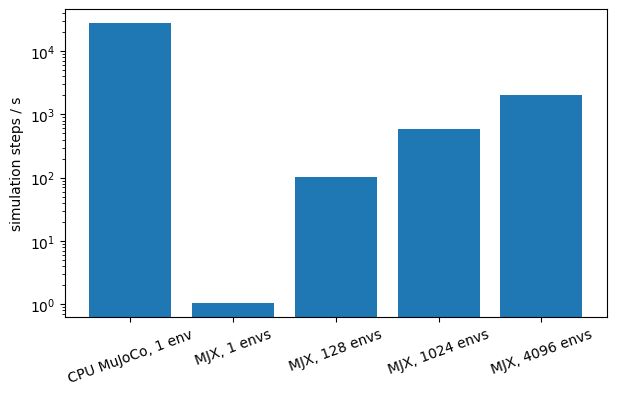

In [4]:
cpu_data = mujoco.MjData(mj_model)
t0 = time.perf_counter(); mujoco.mj_step(mj_model, cpu_data, 2000); cpu_sps = 2000 / (time.perf_counter() - t0)
rows = [("CPU MuJoCo, 1 env", 1, cpu_sps)]
for n_envs in [1, 128, 1024, 4096]:
    keys = jax.random.split(jax.random.PRNGKey(0), n_envs)
    batch = jax.vmap(lambda k: mjx.make_data(mx).replace(qpos=jp.array(mj_model.qpos0) + 0.01 * jax.random.normal(k, (mj_model.nq,))))(keys)
    step = jax.jit(jax.vmap(mjx.step, in_axes=(None, 0)))
    dt = bench(lambda d: step(mx, d), batch, 20)
    rows.append((f"MJX, {n_envs} envs", n_envs, n_envs / dt))
for name, n, sps in rows:
    print(f"{name:22s} {sps:14,.0f} steps/s")
plt.figure(figsize=(7, 4)); plt.bar([r[0] for r in rows], [r[2] for r in rows]); plt.yscale("log"); plt.ylabel("simulation steps / s"); plt.xticks(rotation=20); plt.show()

In [5]:
reset, stepf = jax.jit(env.reset), jax.jit(env.step)
state = reset(jax.random.PRNGKey(0)); traj = [state]
for i in range(150):
    state = stepf(state, jp.zeros(env.action_size)); traj.append(state)
media.show_video(env.render(traj[::2], height=360, width=640, camera="track"), fps=1 / env.dt / 2)
print("zero action = hold the default posture with the PD joint controllers")

Module mujoco.mjx.warp.ffi bc5cef1 load on device 'cuda:0' took 896.53 ms  (compiled)
Module mujoco.mjx.third_party.mujoco_warp._src.smooth 6847a03 load on device 'cuda:0' took 7040.03 ms  (compiled)
Module _nxn_broadphase__locals__kernel_0dcff9d2 0dcff9d load on device 'cuda:0' took 1067.15 ms  (compiled)
Module _nxn_broadphase__locals__kernel_0dcff9d2 1c34f5a load on device 'cuda:0' took 1623.14 ms  (compiled)
Module _primitive_narrowphase__locals__primitive_narrowphase_25442a3d 25442a3 load on device 'cuda:0' took 717.94 ms  (compiled)
Module mujoco.mjx.third_party.mujoco_warp._src.constraint 9feb269 load on device 'cuda:0' took 123.49 ms  (compiled)
Module _friction_dof__locals__kernel_451d1ac6 451d1ac load on device 'cuda:0' took 368.82 ms  (compiled)
Module _limit_slide_hinge__locals__kernel_fb6bdfd1 fb6bdfd load on device 'cuda:0' took 374.39 ms  (compiled)
Module _efc_contact_init__locals__kernel_5b9c0428 5b9c042 load on device 'cuda:0' took 231.01 ms  (compiled)
Module _efc_co

100%|██████████| 76/76 [01:02<00:00,  1.22it/s]


This browser does not support the video tag.


zero action = hold the default posture with the PD joint controllers
